Monte 3 gráficos com base no arquivo anexado com as médias de alunos e turmas, contendo as seguintes informações:
1. Monte um gráfico que mostre as maiores e menores médias de cada curso (qualquer gráfico);
2. Monte um gráico que PLOT que tenha duas linhas, precisa marcar no gráfico as duas maiores notas de todos os alunos com um marker e texto informando a maior nota:
a) Todas as notas de alunos do curso de Design
b) Todas as notas de alunos do curso de Java
3. Monte um gráfico em pizza que mostre em % quantos alunos passaram e quantos reprovaram apenas no curso de Python (média 7)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_alunos = pd.read_csv("alunos_senai_sig.csv")

QUESTÃO 01

Curso
Design            7.333333
Banco de Dados    7.130000
Java              6.966667
Python            6.115000
Name: Media_Final, dtype: float64


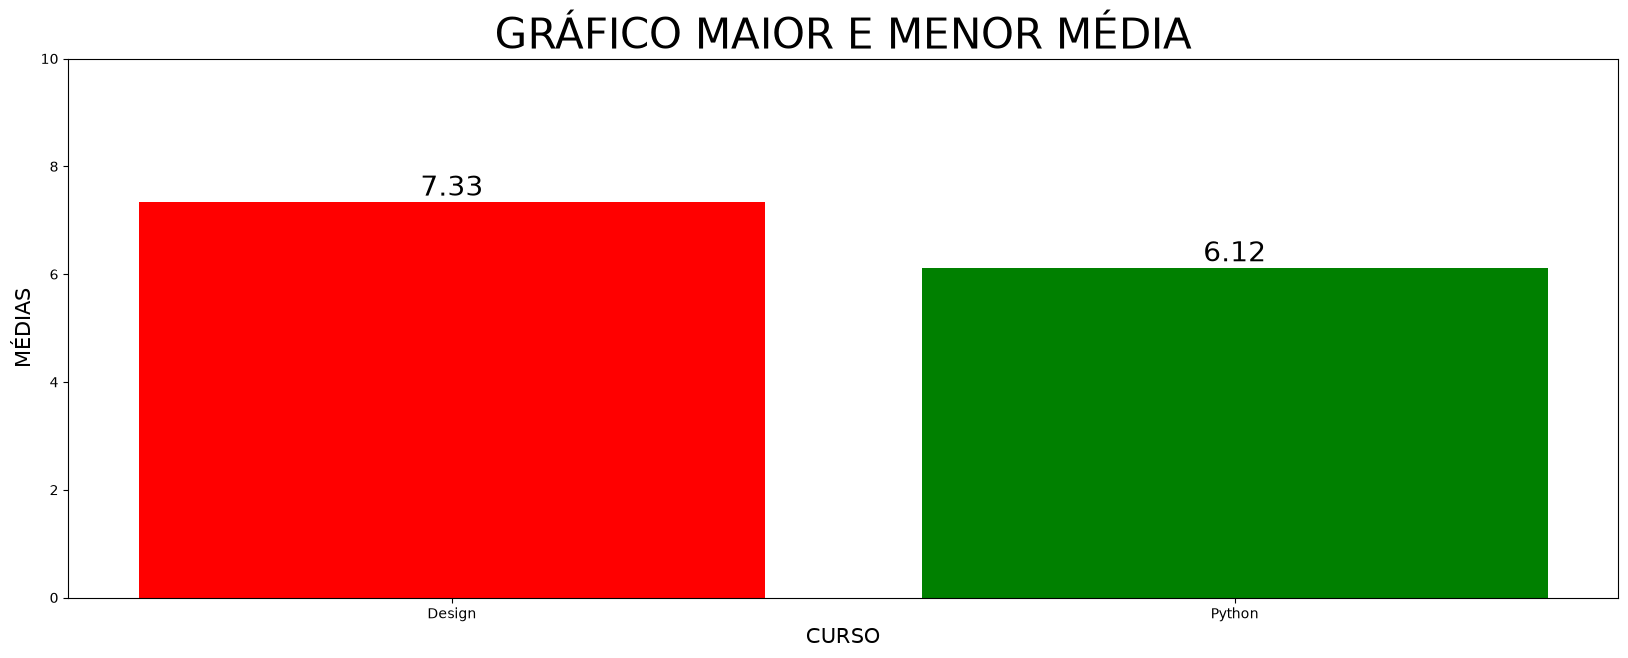

In [7]:
media_por_curso = df_alunos.groupby("Curso")["Media_Final"].mean().sort_values(ascending=False)

print(media_por_curso)

curso_maior_media = media_por_curso.idxmax()
maior_media = media_por_curso.max()
curso_menor_media = media_por_curso.idxmin()
menor_media = media_por_curso.min()



plt.figure(figsize=(20,7))

barra = plt.bar(
    [curso_maior_media, curso_menor_media],
    [maior_media, menor_media],
    color=["r", "g"]
)

#plt.title = ("MÉDIAS POR TURMA")
#plt.ylabel =  ("NOTAS")
#plt.xlabel = ("MÉDIA FINAL")
#plt.show()
#print(type(barra))

for coluna in barra:
    yvalor = coluna.get_height()

    plt.text(
        coluna.get_x() + coluna.get_width() / 2,
        yvalor,
        f"{yvalor:.2f}",
        fontsize=20,
        ha="center",
        va="bottom"
    )


plt.title ("GRÁFICO MAIOR E MENOR MÉDIA", fontsize=30)
plt.ylabel  ("MÉDIAS", fontsize=15)
plt.xlabel ("CURSO", fontsize=15)
plt.ylim(0,10)



plt.show()

QUESTÃO 02

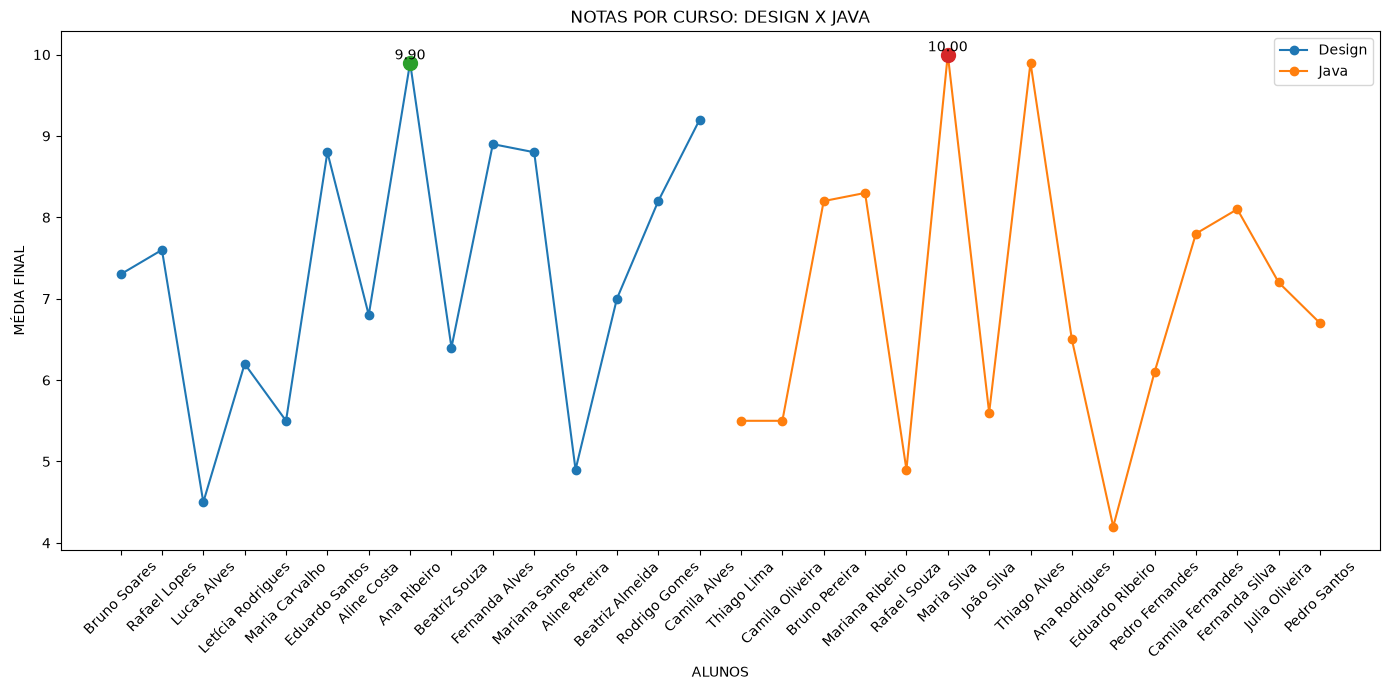

In [24]:
design = df_alunos[df_alunos["Curso"] == "Design"]
java = df_alunos[df_alunos["Curso"] == "Java"]


plt.figure(figsize=(14, 7))


plt.plot(
    design["Nome"],
    design["Media_Final"],
    label="Design",
    marker="o"
)


plt.plot(
    java["Nome"],
    java["Media_Final"],
    label="Java",
    marker="o"
)

# Encontrando as 2 maiores notas de Design
top_design = design.nlargest(1, "Media_Final")

# Destacando as maiores notas de Design
for _, aluno in top_design.iterrows():
    plt.plot(
        aluno["Nome"],
        aluno["Media_Final"],
        marker="o",
        markersize=10
    )

    plt.text(
        aluno["Nome"],
        aluno["Media_Final"],
        f'{aluno["Media_Final"]:.2f}',
        ha="center",
        va="bottom"
    )

# Encontrando as 2 maiores notas de Java
top_java = java.nlargest(1, "Media_Final")

# Destacando as maiores notas de Java
for _, aluno in top_java.iterrows():
    plt.plot(
        aluno["Nome"],
        aluno["Media_Final"],
        marker="o",
        markersize=10
    )

    plt.text(
        aluno["Nome"],
        aluno["Media_Final"],
        f'{aluno["Media_Final"]:.2f}',
        ha="center",
        va="bottom"
    )

# Configurações do gráfico
plt.title("NOTAS POR CURSO: DESIGN X JAVA")
plt.xlabel("ALUNOS")
plt.ylabel("MÉDIA FINAL")

plt.legend()

# Rotacionando os nomes para melhor visualização
plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

QUESTÃO 3

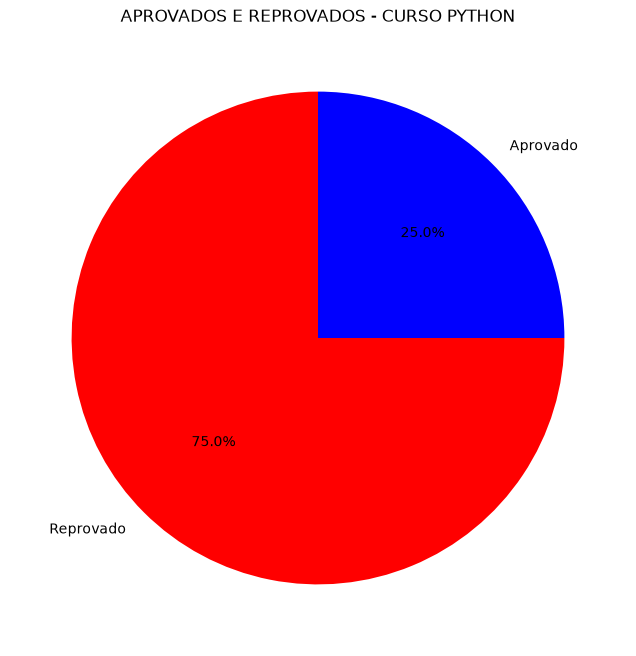

In [23]:
alunos_python = df_alunos[df_alunos["Curso"] == "Python"].copy()

# Criando a coluna Situação utilizando np.where()
alunos_python["Situacao"] = np.where(
    alunos_python["Media_Final"] >= 7,
    "Aprovado",
    "Reprovado"
)

# Contando quantos alunos foram aprovados e reprovados
quantidade = alunos_python["Situacao"].value_counts()

# Criando o gráfico de pizza
plt.figure(figsize=(8, 8))

plt.pie(
    quantidade,
    labels=quantidade.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["r", "b"],
)

# Adicionando o título
plt.title("APROVADOS E REPROVADOS - CURSO PYTHON")

plt.show()